# What's new in PyHealth 2.1 (2/3): calibration, confidence intervals and imbalanced outcomes

A ROC-AUC on one test set is not a result a clinical reviewer can act on. PyHealth 2.1 adds what's missing:

- **Calibration metrics:** are the predicted risks right, not just well ranked?
- **Patient-level bootstrap confidence intervals**, and a paired test for "is model A better than model B?"
- **`set_pos_weight`** for imbalanced outcomes, including a `"balanced"` weight computed from the training data.

**Time:** about 10 minutes on a free Colab CPU runtime.

**How to run:** Runtime > Run all, or Shift+Enter cell by cell. The text above each code cell says what it does; the text below says how to read its output.

## Visual guide

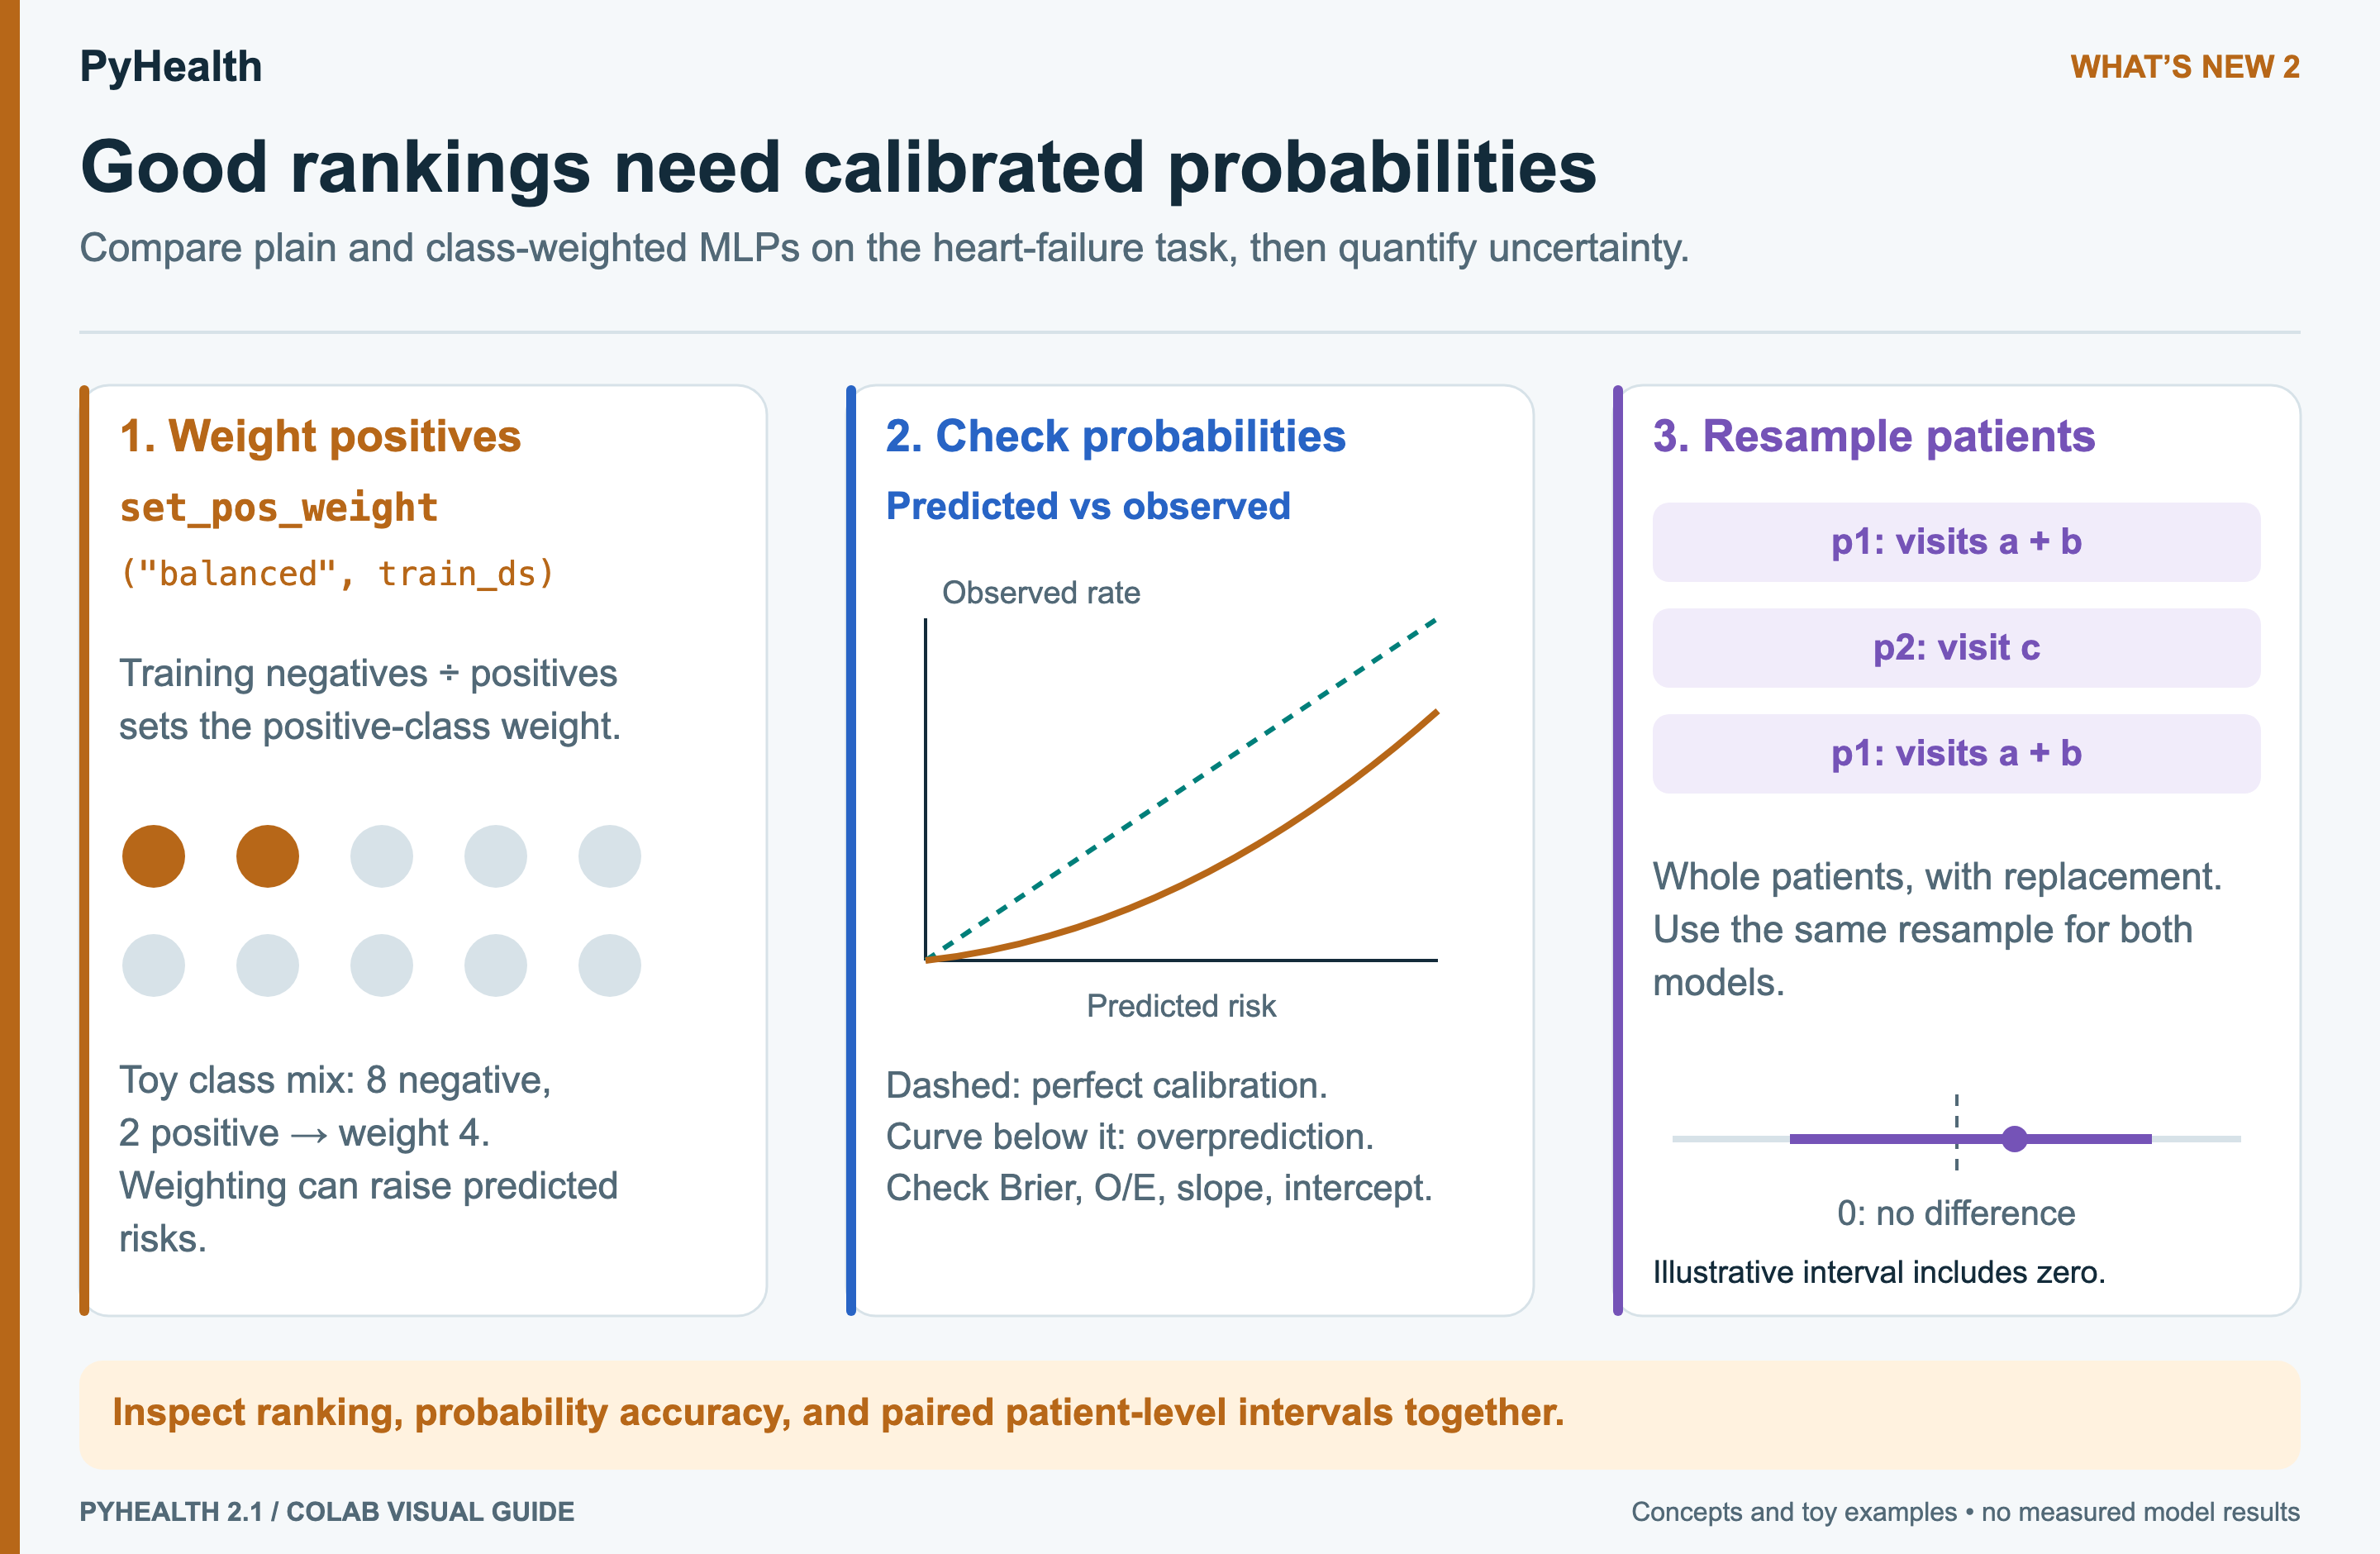

Positive-class weighting changes the loss and can affect probabilities. Calibration complements discrimination; grouped, paired bootstrap preserves each patient’s visits. All plotted values are conceptual.


## Setup

This installs **PyHealth 2.1.0** from PyPI. On Colab choose **Runtime > Run all**. If the install has to upgrade a package Colab already loaded, the runtime restarts once ("Your session crashed"); choose **Runtime > Run all** again. Output is kept short: PyHealth's step-by-step build logs are hidden.

In [1]:
# Installs PyHealth 2.1.0 from PyPI (about 1-2 minutes the first time).
# If the install upgrades a package Python has already loaded (Colab
# preloads a few, such as numpy), the runtime restarts once: Colab then
# shows "Your session crashed". That is expected. Choose Runtime > Run all
# again and everything runs through; this cell will then skip the install.
import importlib.metadata as md
import os
import subprocess
import sys

PYHEALTH_VERSION = "2.1.0"
EXTRAS = "xgboost"


def installed(dist):
    try:
        return md.version(dist)
    except md.PackageNotFoundError:
        return None


if installed("pyhealth") != PYHEALTH_VERSION:
    # Remember which installed packages are already imported, and at what version.
    owners = md.packages_distributions()
    loaded = {}
    for module in list(sys.modules):
        for dist in owners.get(module, []):
            loaded[dist] = installed(dist)

    print(f"Installing PyHealth {PYHEALTH_VERSION}...")
    result = subprocess.run(
        # ipywidgets draws the progress bars while a dataset is built; Colab
        # already has it, other Jupyter setups may not.
        [sys.executable, "-m", "pip", "install", "-q",
         f"pyhealth[{EXTRAS}]=={PYHEALTH_VERSION}", "ipywidgets"],
        capture_output=True, text=True,
    )
    if result.returncode != 0:
        print(result.stdout[-5000:], result.stderr[-5000:])
        raise RuntimeError("Installing PyHealth failed; see the log above.")

    changed = sorted(d for d, v in loaded.items() if installed(d) != v)
    if changed:
        print("Upgraded packages that were already loaded:", ", ".join(changed))
        print("Restarting the runtime. When Colab says the session crashed, "
              "choose Runtime > Run all again.")
        os.kill(os.getpid(), 9)  # Colab restarts the runtime automatically

import logging
import warnings

import pyhealth
import torch

# Keep the output readable: hide the step-by-step logs of dataset and task
# building (progress bars still show), keep the per-epoch training scores,
# and skip the printout of every model's layers. To see everything, run
# logging.getLogger("pyhealth").setLevel(logging.INFO)
logging.getLogger("pyhealth").setLevel(logging.WARNING)
logging.getLogger("pyhealth.trainer").setLevel(logging.INFO)
logging.getLogger("pyhealth.trainer").addFilter(
    lambda record: not isinstance(record.msg, torch.nn.Module))
# PyHealth 2.1.0 pins litdata, which then suggests upgrading on every run.
warnings.filterwarnings("ignore", message="A newer version of litdata")
print(f"PyHealth {installed('pyhealth')} is ready | "
      f"device: {'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU'}")

Installing PyHealth 2.1.0...
PyHealth 2.1.0 is ready | device: CPU


## Load the data and define the task

The public synthetic copy of MIMIC-III (no credentials). The question, from Tutorial 04: **does an admission include a heart-failure diagnosis, judged from its medications and procedures?** It is a custom task in about 25 lines, and it has real signal, unlike synthetic mortality, which is close to random. Admissions are split by patient, with preprocessing fitted on training patients only (part 1 of this series). The first run downloads and caches the tables (a few minutes).

In [2]:
from collections import defaultdict

from pyhealth.datasets import MIMIC3Dataset, PatientSplit, get_dataloader
from pyhealth.tasks import BaseTask


class HeartFailureFromMedications(BaseTask):
    """Does an admission include a heart-failure diagnosis (ICD-9 428.x)?"""

    task_name = "HeartFailureFromMedications"
    input_schema = {"drugs": "sequence", "procedures": "sequence"}
    output_schema = {"heart_failure": "binary"}

    def __call__(self, patient):
        by_admission = defaultdict(lambda: {"drugs": [], "diagnoses": [], "procedures": []})
        for e in patient.get_events(event_type="prescriptions"):
            if e.drug:
                by_admission[e.hadm_id]["drugs"].append(e.drug)
        for e in patient.get_events(event_type="diagnoses_icd"):
            by_admission[e.hadm_id]["diagnoses"].append(e.icd9_code)
        for e in patient.get_events(event_type="procedures_icd"):
            by_admission[e.hadm_id]["procedures"].append(e.icd9_code)
        return [
            {
                "patient_id": patient.patient_id,
                "visit_id": hadm_id,
                "drugs": codes["drugs"],
                "procedures": codes["procedures"] or ["none"],
                "heart_failure": int(any(c.startswith("428") for c in codes["diagnoses"])),
            }
            for hadm_id, codes in by_admission.items()
            if codes["drugs"] and codes["diagnoses"]
        ]


dataset = MIMIC3Dataset(
    root="https://storage.googleapis.com/pyhealth/Synthetic_MIMIC-III",
    tables=["diagnoses_icd", "procedures_icd", "prescriptions"],
    cache_dir="pyhealth_cache",
)
train_ds, val_ds, test_ds = dataset.set_task(
    HeartFailureFromMedications(), split=PatientSplit((0.7, 0.1, 0.2), seed=7)
)
val_loader = get_dataloader(val_ds, batch_size=512)
test_loader = get_dataloader(test_ds, batch_size=512)
train_loader = get_dataloader(train_ds, batch_size=256, shuffle=True)
positives = sum(int(train_ds[i]["heart_failure"]) for i in range(len(train_ds)))
print(f"train {len(train_ds)}  val {len(val_ds)}  test {len(test_ds)} admissions")
print(f"{positives / len(train_ds):.1%} of training admissions are positive")

/usr/local/lib/python3.13/dist-packages/pyhealth/datasets/mimic3.py:59: UserWarning: Events from prescriptions table only have date timestamp (no specific time). This may affect temporal ordering of events.
  warnings.warn(
  0%|          | 0/49993 [00:00<?, ?it/s]

Rank 0 inferred the following `['bytes']` data format.


  0%|          | 0/50610 [00:00<?, ?it/s]

Rank 0 inferred the following `['no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:1', 'bytes']` data format.


100%|██████████| 50610/50610 [00:08<00:00, 6157.23it/s]


train 35415  val 5065  test 10130 admissions
20.8% of training admissions are positive


## 1. Imbalanced outcomes: `set_pos_weight`

When positives are a minority, the loss is dominated by negatives. `set_pos_weight` weights each positive example more. It accepts a number, one number per label, or `"balanced"` (negatives / positives), which is computed from the dataset you pass, so pass the **training** set, never the test set.

In [3]:
import torch
from pyhealth.models import MLP
from pyhealth.trainer import Trainer


def train(model):
    trainer = Trainer(model=model, metrics=["pr_auc", "roc_auc"], enable_logging=False)
    trainer.train(train_dataloader=train_loader, val_dataloader=val_loader,
                  epochs=4, monitor="pr_auc", patience=2)
    return trainer


torch.manual_seed(0)
plain = train(MLP(dataset=train_ds))

torch.manual_seed(0)
weighted_model = MLP(dataset=train_ds)
weighted_model.set_pos_weight("balanced", train_ds)
print(f"balanced positive weight: {float(weighted_model.pos_weight[0]):.1f}")
weighted = train(weighted_model)

Metrics: ['pr_auc', 'roc_auc']
Device: cpu

Training:
Batch size: 256
Optimizer: <class 'torch.optim.adam.Adam'>
Optimizer params: {'lr': 0.001}
Weight decay: 0.0
Max grad norm: None
Val dataloader: <pyhealth.datasets.utils._SeededDataLoader object at 0x7a9276fd6a50>
Monitor: pr_auc
Monitor criterion: max
Epochs: 4
Patience: 2



Epoch 0 / 4:   0%|          | 0/139 [00:00<?, ?it/s]

--- Train epoch-0, step-139 ---
loss: 0.4832


Evaluation: 100%|██████████| 10/10 [00:00<00:00, 11.05it/s]

--- Eval epoch-0, step-139 ---
pr_auc: 0.4809
roc_auc: 0.7309
loss: 0.4550
New best pr_auc score (0.4809) at epoch-0, step-139



...

--- Eval epoch-2, step-417 ---
pr_auc: 0.4703
roc_auc: 0.7346
loss: 0.9723



Epoch 3 / 4:   0%|          | 0/139 [00:00<?, ?it/s]

--- Train epoch-3, step-556 ---
loss: 0.8968


Evaluation: 100%|██████████| 10/10 [00:01<00:00,  9.61it/s]

--- Eval epoch-3, step-556 ---
pr_auc: 0.4739
roc_auc: 0.7318
loss: 0.9674
New best pr_auc score (0.4739) at epoch-3, step-556
Loaded best model (kept in memory)


## 2. Discrimination and calibration

`binary_metrics_fn` now also reports calibration:

| Metric | Ideal | Reading it |
|---|---|---|
| `brier` | 0 | mean squared error of the probabilities |
| `oe_ratio` | 1 | observed / expected events; below 1 means risks are overestimated |
| `calibration_slope` | 1 | below 1 means predictions are too extreme |
| `calibration_intercept` | 0 | above 0 means risks are underestimated overall |

In [4]:
from pyhealth.metrics import binary_metrics_fn

METRICS = ["pr_auc", "roc_auc", "brier", "oe_ratio", "calibration_slope", "calibration_intercept"]
y_true, p_plain, _, pids = plain.inference(test_loader, return_patient_ids=True)
_, p_weighted, _ = weighted.inference(test_loader)
y_true, p_plain, p_weighted = y_true.ravel(), p_plain.ravel(), p_weighted.ravel()

m_plain = binary_metrics_fn(y_true, p_plain, metrics=METRICS)
m_weighted = binary_metrics_fn(y_true, p_weighted, metrics=METRICS)
print(f"{'metric':22s} {'plain':>8s} {'weighted':>9s}")
for m in METRICS:
    print(f"{m:22s} {m_plain[m]:8.3f} {m_weighted[m]:9.3f}")
print(f"\nmean predicted risk: plain {p_plain.mean():.3f}, weighted {p_weighted.mean():.3f}, "
      f"observed {y_true.mean():.3f}")

Evaluation: 100%|██████████| 20/20 [00:02<00:00,  9.69it/s]


metric                    plain  weighted
pr_auc                    0.446     0.436
roc_auc                   0.726     0.722
brier                     0.142     0.208
oe_ratio                  0.929     0.459
calibration_slope         0.823     0.835
calibration_intercept    -0.111    -1.374

mean predicted risk: plain 0.218, weighted 0.442, observed 0.203


**Reading it:** the two models rank admissions about equally well (ROC-AUC, PR-AUC), but weighting pushes every probability up: the weighted model's mean risk is well above the observed rate, its observed/expected ratio drops below 1, and its Brier score gets worse. That is the price of weighting: use it for ranking, and recalibrate (on a calibration split, see part 1) before reading the numbers as risks.

## 3. Confidence intervals that respect patients

Samples from the same patient are correlated, so the bootstrap should resample **whole patients**: pass `groups=` the patient ids. `paired_bootstrap_diff` compares two models on the same resampled patients.

In [5]:
import numpy as np
from pyhealth.metrics import bootstrap_ci, paired_bootstrap_diff

groups = np.asarray(pids)
for name, p in [("plain", p_plain), ("weighted", p_weighted)]:
    ci = bootstrap_ci(y_true, p, "roc_auc", groups=groups, n_boot=500, seed=0)
    print(f"{name:9s} ROC-AUC {ci['estimate']:.3f}  95% CI [{ci['lower']:.3f}, {ci['upper']:.3f}]")

d = paired_bootstrap_diff(y_true, p_weighted, p_plain, "roc_auc", groups=groups, n_boot=500, seed=0)
print(f"\nweighted - plain: {d['estimate']:+.3f}  95% CI [{d['lower']:+.3f}, {d['upper']:+.3f}]")

plain     ROC-AUC 0.726  95% CI [0.713, 0.738]
weighted  ROC-AUC 0.722  95% CI [0.709, 0.735]

weighted - plain: -0.004  95% CI [-0.009, +0.001]


**Reading it:** each interval says how much the score could move on another sample of patients like these. If the interval of the difference includes 0, this test set cannot tell the two models apart: worth knowing before claiming a winner. With a few hundred patients and a rare outcome, such as mortality in Tutorial 03, the intervals get much wider.

## Summary

- `model.set_pos_weight("balanced", train_ds)` handles imbalanced outcomes; check calibration afterwards.
- `binary_metrics_fn` reports `brier`, `oe_ratio`, `calibration_slope` and `calibration_intercept`.
- `bootstrap_ci(..., groups=patient_ids)` and `paired_bootstrap_diff` give intervals that respect patients.

## The series

All three notebooks open in Colab from [pyhealth.dev/tutorials.html#whats-new](https://pyhealth.dev/tutorials.html#whats-new):

1. Splits you can trust, runs you can repeat
2. Calibration, confidence intervals and imbalanced outcomes
3. XGBoost with exact explanations, medical-code translation and new processors

Want the full course? The nine [PyHealth tutorials](https://pyhealth.dev/tutorials.html) go deeper on every topic. Release notes: [PyHealth 2.1.0 on GitHub](https://github.com/sunlabuiuc/PyHealth/releases/tag/v2.1.0).